# Foundations of Deep Learning — Exercise Sheet 1 (Part B: Programming)

This notebook contains Task 4 of Exercise Sheet 1.

* Fill in all parts marked with `TODO`.
* Before the presentation: **Restart the kernel and run all cells** (`Kernel → Restart & Run All`) so that all outputs are visible.
* You need `numpy` and `matplotlib`. On Google Colab everything is pre-installed.
* Every group member must be able to explain every line of code in this notebook.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

---
## Task 1: Dot Products and Gradients

### 1(a): Pridictions using dot products
Each prediction is the dot product of one row  of $x$ with $\theta$:

$$
\begin{aligned}
  \hat y_1 &= 1(0.2) + 25(0.64) + 50(0) + 2(1) + 50(0.14) = 25.2 \\
  \hat y_1 &= 1(0.2) + -10(0.64) + 50(0) + 0(1) + 10(0.14) = -4.8
\end{aligned}
$$
With that we get $\hat{\mathbf y} = X\theta = (25.2, -4.8)^\top$


### 1(b)(i): Partial derivatives and gradient
Define $g = \theta_1 + 2\theta_2 -3$ so that $f(\theta)=g^2$ and with the chain rule we get the following:

$$
\begin{aligned}
  \frac{\partial f}{\partial \theta_1} = 2(\theta_1 + 2\theta_2 -3) \\
  \frac{\partial f}{\partial \theta_2} = 4(\theta_1 + 2\theta_2 -3) \\
\end{aligned}
$$

And with that we get:
$$
\nabla_\theta f = \begin{pmatrix}2g\\4g\end{pmatrix}
$$

At $\theta=(1,0)^\top$ we have $$g=1+2(0)-3=-2$ and

$$
f((1,0)^\top)=4
\qquad
\nabla_\theta f =(-4,-8)^\top
$$



### 1(b)(ii): One gradient descent step

For each learning rate, start independently from $\theta=(1,0)^\top$:

$$
\theta_{\mathrm{new}}
= \theta - \eta\nabla_\theta f
= \begin{pmatrix}1\\0\end{pmatrix}-\eta\begin{pmatrix}-4\\-8\end{pmatrix}
= \begin{pmatrix}1+4\eta\\8\eta\end{pmatrix}
$$
$\eta = 0.1: f(1.4, 0.8)=(1.4+1.6-3)^2 = 0$

$\eta = 0.2: f(1.8, 1.6)=(1.8+3.2-3)^2 = 4$

$\eta = 0.3: f(2.2, 2.4)=(2.2+4.8-3)^2 = 16$

For $\eta = 0.1$ the error get smaller but with the higher learning rates we overshoot the "local" minimum and the error
increases again.

---
## Task 2: The Perceptron and the XOR Problem

## (a) Classification and Decision Boundary

Given $\theta = (-1, 2, 1)$ so that we get $c(x) = h(-1 + 2x_1 + x_2)$


| $x_1$ | $x_2$ | $z$ | $h(z)$ |
|-------|-------|-----|--------|
| 0     | 0     | -1  | 0      |
| 1 | 0 | 1 | 1 |
| 0 | 1 | 0 | 1 |
| 1 | 1 | 2 | 1 |

for the plot see the matplotlib plot below.

If we drop $\theta_0 $ we have $c(x)=h(2x_1 + x_2)$ and the decision boundary becomes $x_2 = -2x_1$ and it now passes through the origin at $(0,0)$ andall points are classified as 1.


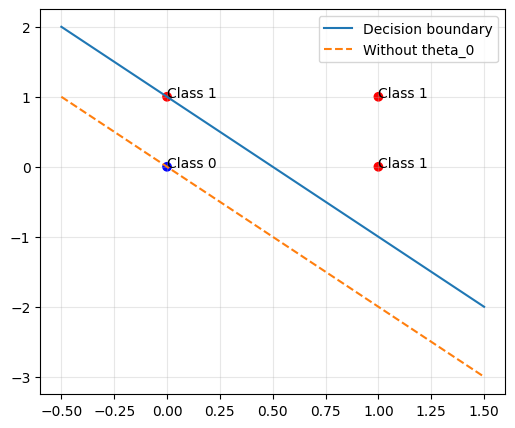

In [ ]:
# Input points
points = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

# Parameter theta (first is bias)
theta = np.array([-1, 2, 1])

# @ is the dot product
z = theta[0] + points @ theta[1:]

# Apply step function and use `astype to cast bool to int`
labels = (z >= 0).astype(int)

# Create 200 x values to draw a smooth line
x1 = np.linspace(-0.5, 1.5, 200)

# Set z=0 and rearrange for x2
x2 = -(theta[0] + theta[1] *x1) / theta[2]

plt.figure(figsize=(6,5))
plt.plot(x1, x2, label="Decision boundary")
# Decision boundary without bias: 2*x1 + x2 = 0
plt.plot(x1, -2*x1, "--", label="Without theta_0")


plt.scatter(points[:, 0], points[:,1], c=labels, cmap="bwr")

for(a,b), label in zip(points, labels):
  plt.annotate(f"Class {label}", (a,b))

plt.grid(alpha=0.3)
plt.legend()
plt.show()

## (b) AND, OR and NAND

For AND the output is 1 if both inputs are 1 so for that we choose $\theta_0=-2, \theta_1=1, \theta_2=1$ and with that we get $c_{\text{AND}}(x)=h(-2+x_1+x_2)$.

| $x_1$ | $x_2$ | $z$ | $h(z)$|
|---|---|---|---|
| 0 | 0 | -2 | 0 |
| 0 | 1 | -1 | 0 |
| 1 | 0 | -1 | 0 |
| 1 | 1 | 0 | 1 |


For OR the output is 1 if at least one input is 1 so for that we choose $\theta_0=-1, \theta_1=1, \theta_2=1$ and with that we get $c_{\text{OR}}(x)=h(-1+x_1+x_2)$.

| $x_1$ | $x_2$ | $z$ | $h(z)$|
|---|---|---|---|
| 0 | 0 | -1 | 0 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | 1 | 1 |


NAND(NOT AND) outputs 0 only if both inputs are 1 so for that we choose $\theta_0=1, \theta_1=-1, \theta_2=-1$ and with that we get $c_{\text{NAND}}(x)=h(1-x_1-x_2)$.

| $x_1$ | $x_2$ | $z$ | $h(z)$|
|---|---|---|---|
| 0 | 0 | 1 | 1 |
| 0 | 1 | 0 | 1 |
| 1 | 0 | 0 | 1 |
| 1 | 1 | -1 | 0 |



## (c) XOR

XOR only outputs 1 if exactly one input is 1 and we have the following table:
| $x_1$ | $x_2$ | XOR |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

With the definition of the perceptrion of $c(x)=h(\theta_0+\theta_1x_1+\theta_2x_2)$ and $h(z)=1$ if $z\geq0$, otherwise $h(z)=0$.


To show that one perceptron can't compute XOR we use a proof by contradiction.
Assume there exists $\theta=(\theta_0,\theta_1,\theta_2)$ that solves XOR. Therefore we have the following inequalities:
1. Line: $\theta_0 + \theta_1 \cdot 0 + \theta_2 \cdot 0 < 0$ which leads to $\theta_0 < 0$
2. Line: $\theta_0 + \theta_1 \cdot 0 + \theta_2 \cdot 1 \geq 0$ so that $\theta_0 + \theta_2 \geq 0$
3. Line: $\theta_0 + \theta_1 \cdot 1 + \theta_2 \cdot 0 \geq 0$ so that $\theta_0 + \theta_1 \geq 0$
4. Line: $\theta_0 + \theta_1 \cdot 1 + \theta_2 \cdot 1 < 0$ so that $\theta_0 + \theta_1 + \theta_2 < 0$

We start by adding inequalitie 2 and 3 so that we get $(\theta_0+\theta_2)+(\theta_0+\theta_1)\geq0$ which is $2\theta_0+\theta_1+\theta_2\geq0$. Following we subtract $\theta_0$ so that we have $\theta_0+\theta_1+\theta_2\geq-\theta_0$.

From the first inequalitie we know that $\theta_0<0 \implies - \theta_0 >0$. Therefore we know that our rearranged inequalitie from above implies $\theta_0+\theta_1+\theta_2>0$ which contradicts the inequalitie 4 which requires $\theta_0+\theta_1+\theta_2<0$.

Therefore there is no $\theta$ which can fulfill all inequalites and therefore a single perceptron can't compoute XOR.

## (d): XOR
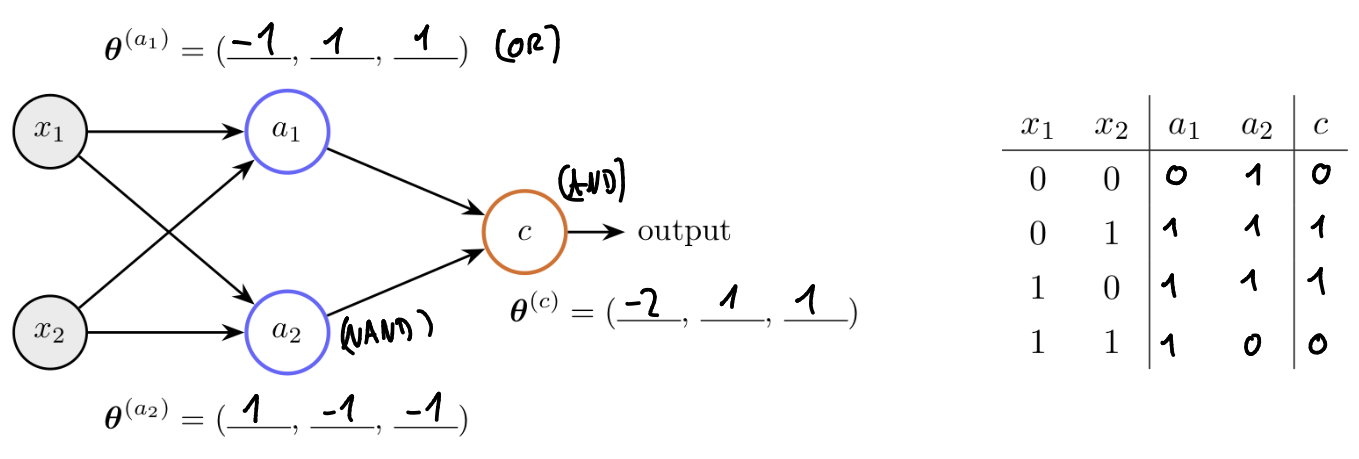

---
## Task 3: Machine Learning Basics

---
## Task 4: Perceptrons in NumPy

### 4(a) A vectorized perceptron

Implement the step function $h$ and the perceptron $c(\mathbf{x}) = h(\theta_0 + \theta_1 x_1 + \theta_2 x_2)$ from Task 2.
`perceptron` should classify **all** rows of `X` at once — do not use a loop.

In [ ]:
def step(z):
    """Element-wise step function: 1 if z >= 0, else 0 (as integer array)."""
    return (z >= 0).astype(int)


def perceptron(X, theta):
    """
    X:     array of shape (n, 2), one data point per row
    theta: array of shape (3,) = (theta_0, theta_1, theta_2)
    returns: array of shape (n,) with predictions in {0, 1}
    """
    return step(theta[0] + X @ theta[1:])

Check your answer to Task 2(a):

In [ ]:
points = np.array([[0, 0], [1, 0], [0, 1], [1, 1]])
print(perceptron(points, np.array([-1.0, 2.0, 1.0])))

[0 1 1 1]


The helper below plots the decision regions of any classifier `predict(X)` together with labeled data points.
You do not need to change it.

In [ ]:
def plot_decision_regions(predict, X, y, title="", ax=None, lim=(-0.5, 1.5)):
    """Colors the plane by the prediction of `predict` and draws the points X with labels y."""
    if ax is None:
        ax = plt.gca()
    grid = np.linspace(*lim, 300)
    xx, yy = np.meshgrid(grid, grid)
    zz = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#9ecae1", "#fdae6b"], alpha=0.6)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="#08519c", marker="o", s=80, label="class 0", edgecolor="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="#d94801", marker="s", s=80, label="class 1", edgecolor="k")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")
    ax.set_title(title)

### 4(b) Logical functions

Enter your parameters for **AND**, **OR** and **NAND** from Task 2(b) and visualize them.

AND correct: True
OR correct: True
NAND correct: True


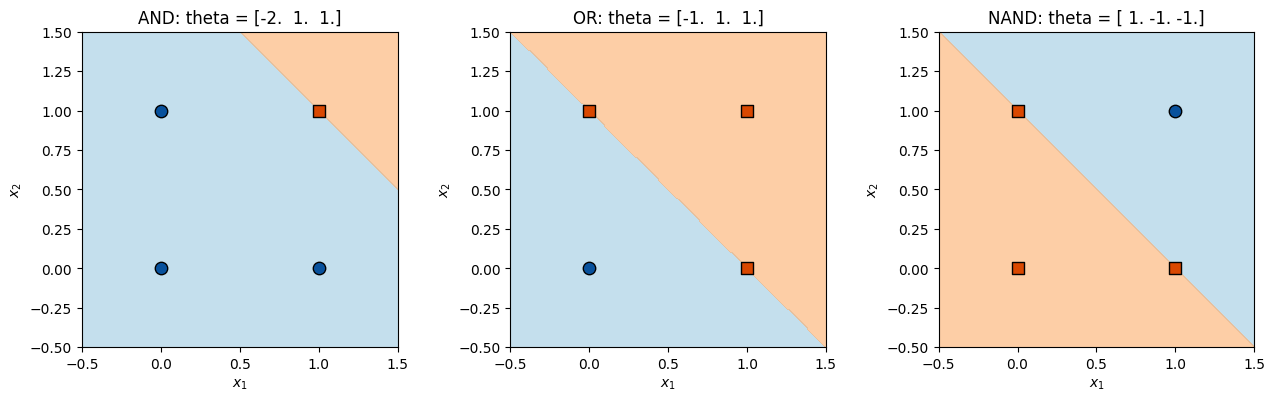

In [ ]:
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and  = np.array([0, 0, 0, 1])
y_or   = np.array([0, 1, 1, 1])
y_nand = np.array([1, 1, 1, 0])

# TODO: your parameters (theta_0, theta_1, theta_2) from Task 2(b)
theta_and  = np.array([-2.0, 1.0, 1.0])
theta_or   = np.array([-1.0, 1.0, 1.0])
theta_nand = np.array([1.0, -1.0, -1.0])

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, theta, y, name in zip(axes, [theta_and, theta_or, theta_nand], [y_and, y_or, y_nand], ["AND", "OR", "NAND"]):
    plot_decision_regions(lambda Z: perceptron(Z, theta), X_bool, y, title=f"{name}: theta = {theta}", ax=ax)
    print(name, "correct:", np.array_equal(perceptron(X_bool, theta), y))
plt.tight_layout()
plt.show()

---
**Done!** Restart the kernel and run all cells before the presentation.